In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

print("Libraries imported successfully!")

Libraries imported successfully!


In [16]:
raw_df = pd.read_csv("/content/bikewale_raw_data.csv")
df = pd.read_csv("/content/bikewale_cleaned_data.csv")

print("Raw Data Shape:", raw_df.shape)
print("Cleaned Data Shape:", df.shape)

Raw Data Shape: (50, 10)
Cleaned Data Shape: (50, 13)


In [17]:
raw_df.head()

,Bike Name,Price,Rating,Ratings Count,Engine CC,Mileage,Power BHP,Torque Nm,Weight KG,URL
0,Yezdi Roadster,201940.0,1.0,217.0,334.00,30.0,28.70,30.00,184.0,https://www.bikewale.com/yezdi-bikes/roadster/
1,TVS Raider 125,86397.0,4.4,2959.0,125.00,56.7,11.20,11.20,123.0,https://www.bikewale.com/tvs-bikes/raider-125/
2,TVS Apache RTR 160,110781.0,4.5,3352.0,159.70,61.0,15.82,13.85,137.0,https://www.bikewale.com/tvs-bikes/apache-160/
3,Bajaj Pulsar N160 2V,122990.0,4.6,1282.0,164.82,51.6,15.68,14.65,148.0,https://www.bikewale.com/bajaj-bikes/pulsar-n160/
4,Royal Enfield Hunter 350,137640.0,4.7,1811.0,349.00,36.2,20.20,27.00,181.0,https://www.bikewale.com/royalenfield-bikes/hu...


In [18]:
df.head()

,Bike Name,Price,Rating,Ratings Count,Engine CC,Mileage,Power BHP,Torque Nm,Weight KG,URL,Brand,Price Category,Engine CC Category
0,Yezdi Roadster,201940.0,1.0,217.0,334.00,30.0,28.70,30.00,184.0,https://www.bikewale.com/yezdi-bikes/roadster/,Yezdi,Premium,300-499 CC
1,TVS Raider 125,86397.0,4.4,2959.0,125.00,56.7,11.20,11.20,123.0,https://www.bikewale.com/tvs-bikes/raider-125/,Tvs,Budget,Below 125 CC
2,TVS Apache RTR 160,110781.0,4.5,3352.0,159.70,61.0,15.82,13.85,137.0,https://www.bikewale.com/tvs-bikes/apache-160/,Tvs,Mid-Range,125-199 CC
3,Bajaj Pulsar N160 2V,122990.0,4.6,1282.0,164.82,51.6,15.68,14.65,148.0,https://www.bikewale.com/bajaj-bikes/pulsar-n160/,Bajaj,Mid-Range,125-199 CC
4,Royal Enfield Hunter 350,137640.0,4.7,1811.0,349.00,36.2,20.20,27.00,181.0,https://www.bikewale.com/royalenfield-bikes/hu...,Royalenfield,Mid-Range,300-499 CC


# DATA UNDERSTANDING

In [19]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

Number of Rows: 50
Number of Columns: 13

Column Names:
['Bike Name', 'Price', 'Rating', 'Ratings Count', 'Engine CC', 'Mileage', 'Power BHP', 'Torque Nm', 'Weight KG', 'URL', 'Brand', 'Price Category', 'Engine CC Category']


In [20]:
df.dtypes

,0
Bike Name,object
Price,float64
Rating,float64
Ratings Count,float64
Engine CC,float64
Mileage,float64
Power BHP,float64
Torque Nm,float64
Weight KG,float64
URL,object


In [21]:
df.describe(include="all")

,Bike Name,Price,Rating,Ratings Count,Engine CC,Mileage,Power BHP,Torque Nm,Weight KG,URL,Brand,Price Category,Engine CC Category
count,50,5.000000e+01,41.000000,39.000000,42.000000,34.000000,42.000000,43.000000,40.000000,50,50,50,42
unique,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50,17,4,5
top,Yezdi Roadster,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://www.bikewale.com/yezdi-bikes/roadster/,Tvs,Budget,Below 125 CC
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,9,20,20
mean,NaN,2.394126e+05,3.546341,1075.871795,278.971667,51.142353,26.538095,25.494651,134.555000,NaN,NaN,NaN,NaN
std,NaN,3.715337e+05,1.611846,1157.382191,261.109546,17.145117,36.347223,25.949273,31.866436,NaN,NaN,NaN,NaN
min,NaN,6.620000e+04,0.000000,6.000000,97.200000,20.000000,7.600000,8.050000,101.000000,NaN,NaN,NaN,NaN
25%,NaN,8.502800e+04,3.600000,229.500000,124.112500,35.300000,8.345000,10.350000,112.000000,NaN,NaN,NaN,NaN
50%,NaN,1.193105e+05,4.400000,762.000000,152.250000,50.000000,11.300000,14.650000,122.500000,NaN,NaN,NaN,NaN
75%,NaN,1.999975e+05,4.600000,1628.500000,349.000000,68.250000,28.175000,27.000000,141.000000,NaN,NaN,NaN,NaN


In [22]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

Missing Values:
Bike Name              0
Price                  0
Rating                 9
Ratings Count         11
Engine CC              8
Mileage               16
Power BHP              8
Torque Nm              7
Weight KG             10
URL                    0
Brand                  0
Price Category         0
Engine CC Category     8
dtype: int64


In [23]:
duplicates = df.duplicated().sum()

print("Duplicate Rows:", duplicates)

Duplicate Rows: 0


# DATA CLEANING CHECK

In [24]:
numeric_columns = [
    "Price",
    "Rating",
    "Ratings Count",
    "Engine CC",
    "Mileage",
    "Power BHP",
    "Torque Nm",
    "Weight KG"
]

df[numeric_columns].describe()

,Price,Rating,Ratings Count,Engine CC,Mileage,Power BHP,Torque Nm,Weight KG
count,5.000000e+01,41.000000,39.000000,42.000000,34.000000,42.000000,43.000000,40.000000
mean,2.394126e+05,3.546341,1075.871795,278.971667,51.142353,26.538095,25.494651,134.555000
std,3.715337e+05,1.611846,1157.382191,261.109546,17.145117,36.347223,25.949273,31.866436
min,6.620000e+04,0.000000,6.000000,97.200000,20.000000,7.600000,8.050000,101.000000
25%,8.502800e+04,3.600000,229.500000,124.112500,35.300000,8.345000,10.350000,112.000000
50%,1.193105e+05,4.400000,762.000000,152.250000,50.000000,11.300000,14.650000,122.500000
75%,1.999975e+05,4.600000,1628.500000,349.000000,68.250000,28.175000,27.000000,141.000000
max,2.000000e+06,4.800000,4561.000000,1200.000000,80.000000,206.000000,130.000000,211.000000


In [25]:
print("Number of Brands:", df["Brand"].nunique())

print("\nBrands:")
print(df["Brand"].unique())

Number of Brands: 17

Brands:
['Yezdi' 'Tvs' 'Bajaj' 'Royalenfield' 'Honda' 'Triumph' 'Hero' 'Yamaha'
 'Jawa' 'Ather' 'Vida' 'River' 'Ola' 'Norton' 'Bmw' 'Benelli' 'Suzuki']


In [26]:
print(df["Price Category"].value_counts())

Price Category
Budget       20
Mid-Range    18
Luxury        7
Premium       5
Name: count, dtype: int64


In [27]:
print(df["Engine CC Category"].value_counts())

Engine CC Category
Below 125 CC    20
300-499 CC       9
125-199 CC       6
500+ CC          6
200-299 CC       1
Name: count, dtype: int64


# EXPLORATORY DATA ANALYSIS

1. Bikes by Brand

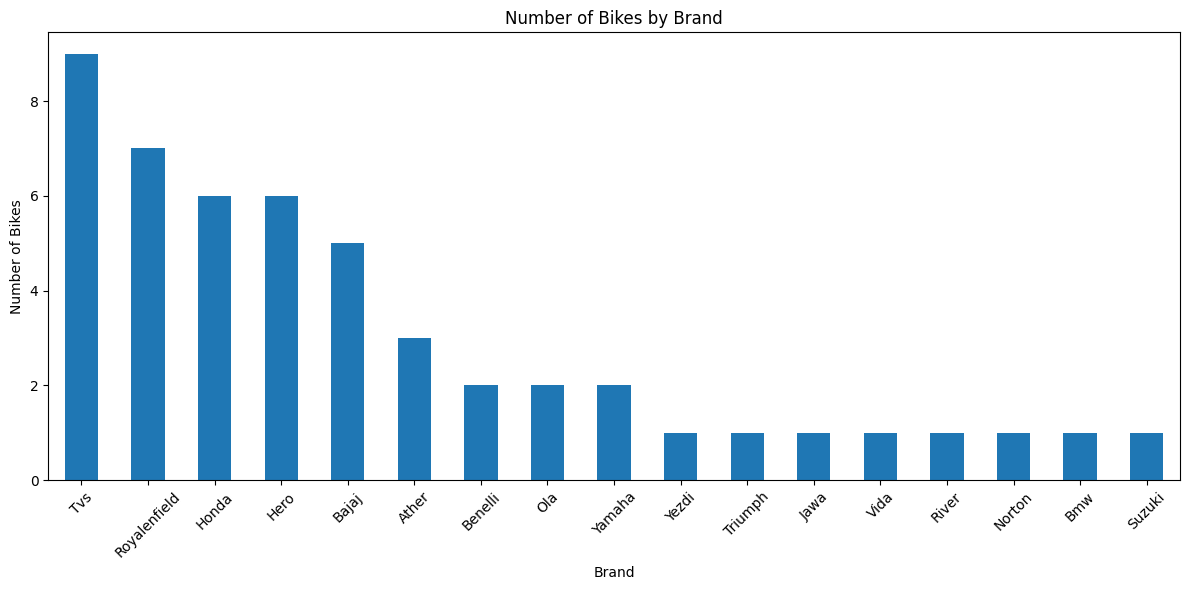

In [28]:
brand_counts = df["Brand"].value_counts()

plt.figure(figsize=(12,6))
brand_counts.plot(kind="bar")

plt.title("Number of Bikes by Brand")
plt.xlabel("Brand")
plt.ylabel("Number of Bikes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

2. Average Price by Brand

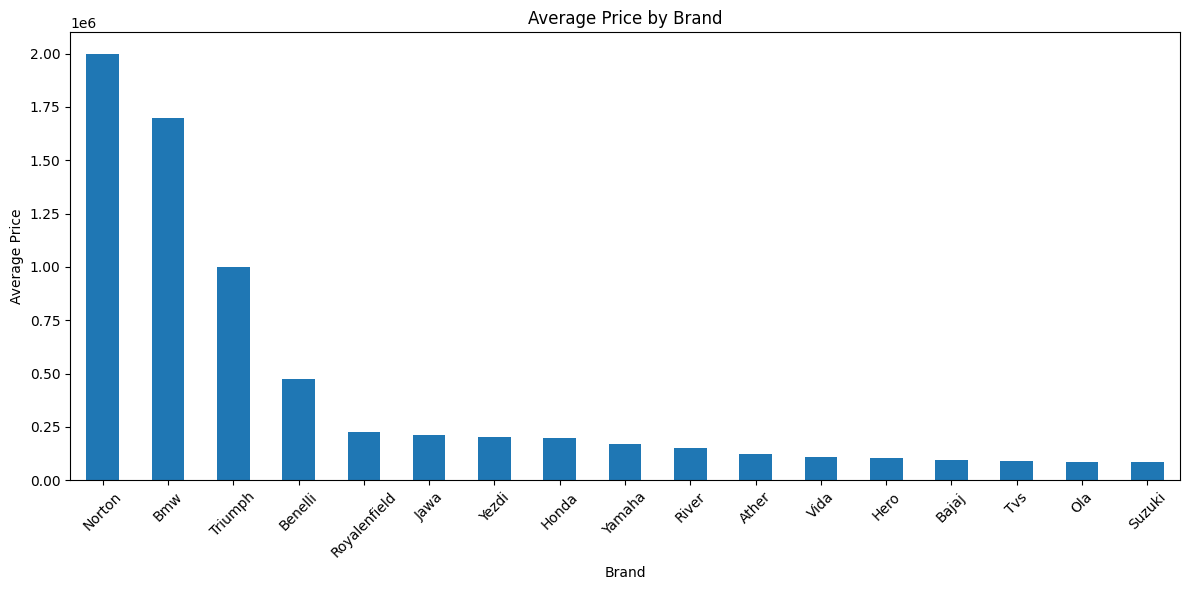

In [29]:
avg_price_brand = (
    df.groupby("Brand")["Price"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12,6))
avg_price_brand.plot(kind="bar")

plt.title("Average Price by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

3. Price vs Mileage

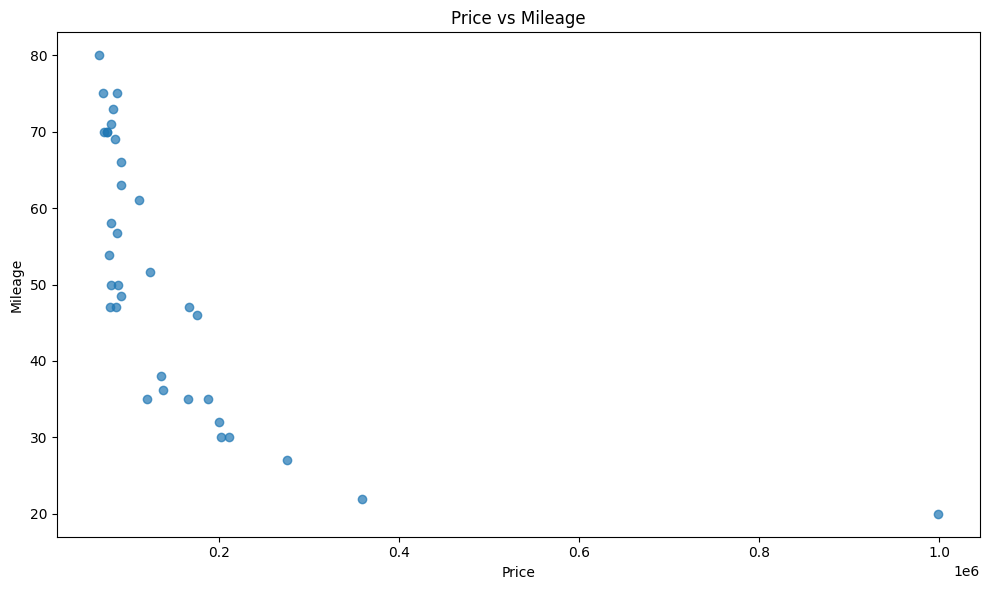

In [30]:
plt.figure(figsize=(10,6))

plt.scatter(
    df["Price"],
    df["Mileage"],
    alpha=0.7
)

plt.title("Price vs Mileage")
plt.xlabel("Price")
plt.ylabel("Mileage")
plt.tight_layout()
plt.show()

4. Price vs Power

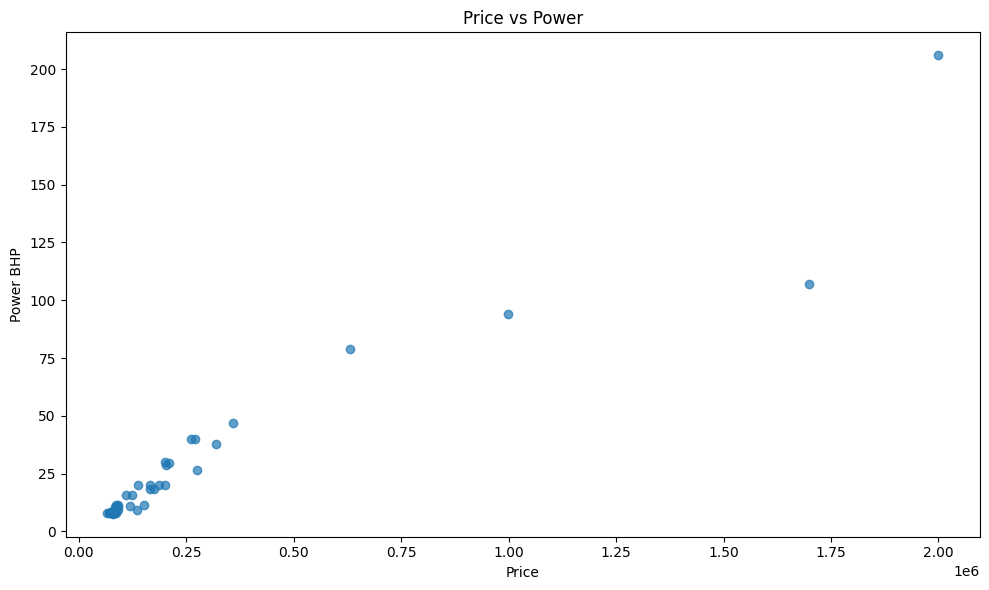

In [31]:
plt.figure(figsize=(10,6))

plt.scatter(
    df["Price"],
    df["Power BHP"],
    alpha=0.7
)

plt.title("Price vs Power")
plt.xlabel("Price")
plt.ylabel("Power BHP")
plt.tight_layout()
plt.show()

5. Engine CC vs Power

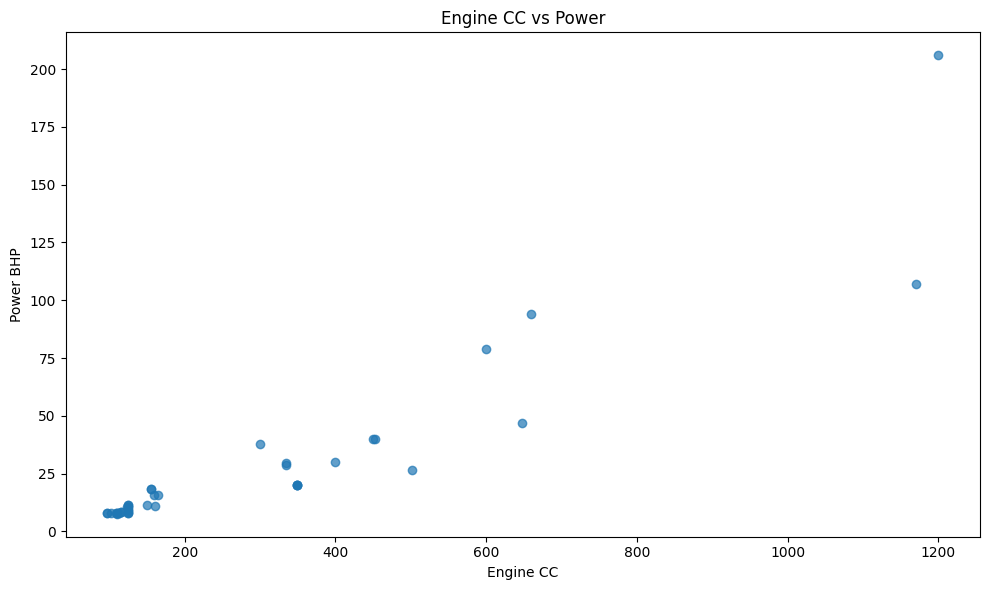

In [32]:
plt.figure(figsize=(10,6))

plt.scatter(
    df["Engine CC"],
    df["Power BHP"],
    alpha=0.7
)

plt.title("Engine CC vs Power")
plt.xlabel("Engine CC")
plt.ylabel("Power BHP")
plt.tight_layout()
plt.show()

# CATEGORY ANALYSIS

6. Engine CC Distribution

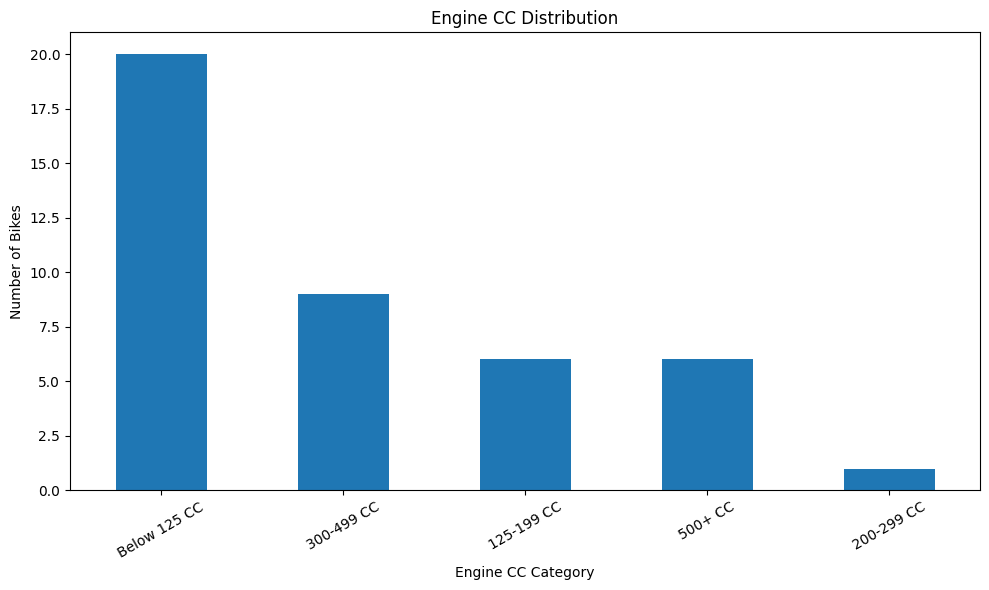

In [33]:
cc_counts = df["Engine CC Category"].value_counts()

plt.figure(figsize=(10,6))

cc_counts.plot(kind="bar")

plt.title("Engine CC Distribution")
plt.xlabel("Engine CC Category")
plt.ylabel("Number of Bikes")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

7. Price Category Analysis

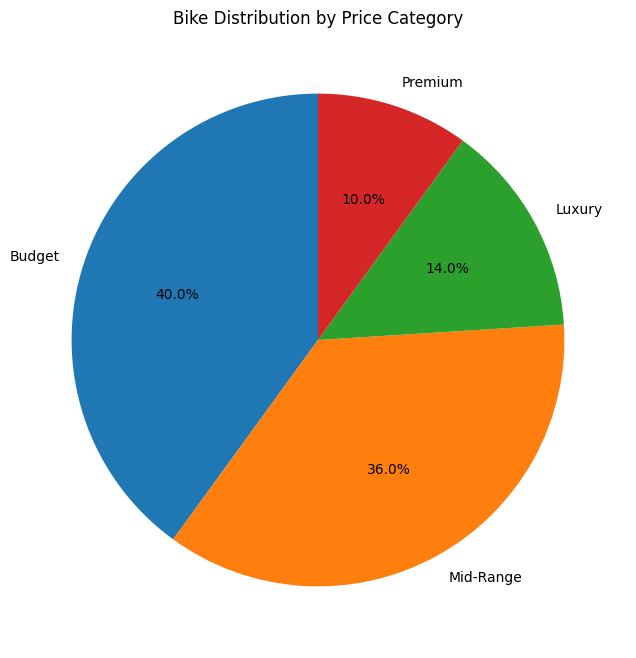

In [34]:
price_category_counts = df["Price Category"].value_counts()

plt.figure(figsize=(8,8))

plt.pie(
    price_category_counts.values,
    labels=price_category_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Bike Distribution by Price Category")
plt.show()

8. Average Mileage by Brand

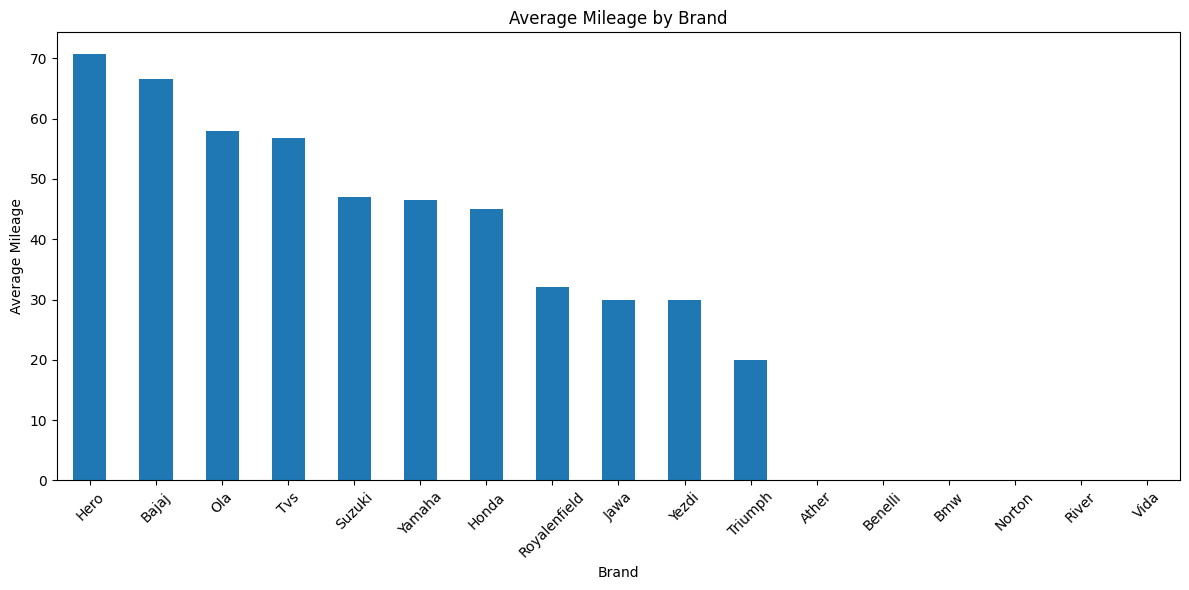

In [35]:
avg_mileage_brand = (
    df.groupby("Brand")["Mileage"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12,6))

avg_mileage_brand.plot(kind="bar")

plt.title("Average Mileage by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Mileage")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# TOP 10 ANALYSIS

9. Top 10 Bikes by Power

In [36]:
top_power = (
    df[["Bike Name", "Power BHP"]]
    .sort_values("Power BHP", ascending=False)
    .head(10)
)

top_power

,Bike Name,Power BHP
32,Norton Manx,206.00
33,BMW R nineT Racer,107.00
8,Triumph Daytona 660,94.00
34,Benelli TNT600i,78.90
13,Royal Enfield Continental GT 650,47.00
30,Royal Enfield Scrambler 450,40.00
28,Royal Enfield Continental GT 450,40.00
35,Benelli TNT 300,37.70
29,Hero Karizma 400,30.00
14,Jawa All Stars 42 Bobber,29.51


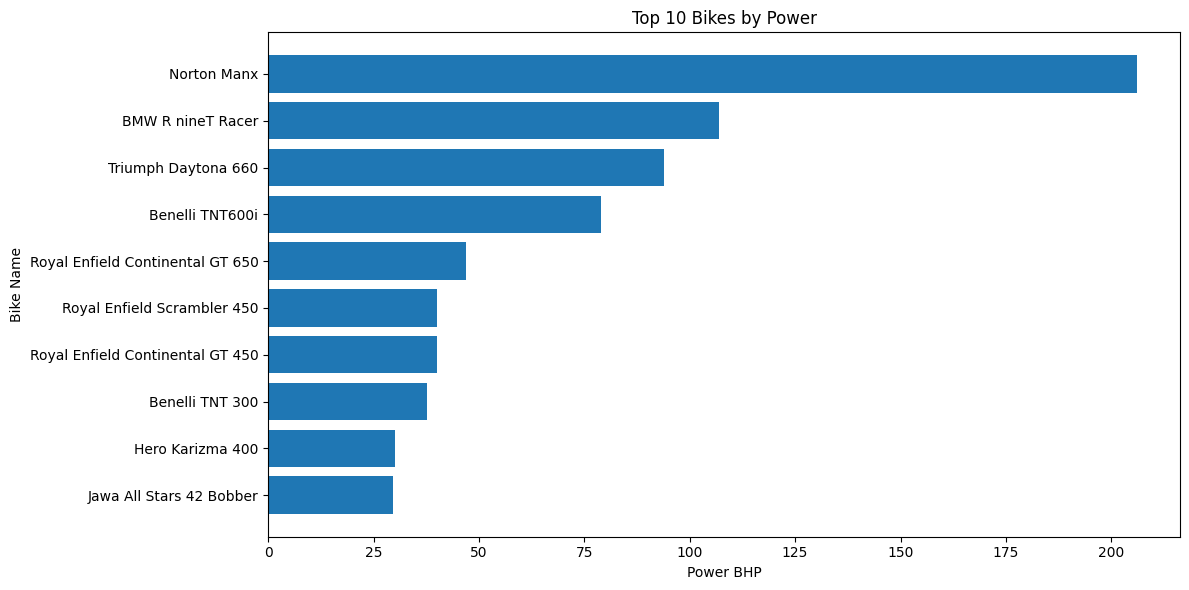

In [37]:
plt.figure(figsize=(12,6))

plt.barh(
    top_power["Bike Name"],
    top_power["Power BHP"]
)

plt.title("Top 10 Bikes by Power")
plt.xlabel("Power BHP")
plt.ylabel("Bike Name")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

10. Top 10 Most Reviewed Bikes

In [38]:
top_reviewed = (
    df[["Bike Name", "Ratings Count"]]
    .sort_values("Ratings Count", ascending=False)
    .head(10)
)

top_reviewed

,Bike Name,Ratings Count
10,Honda SP 125,4561.0
36,Honda Activa,4289.0
2,TVS Apache RTR 160,3352.0
1,TVS Raider 125,2959.0
37,TVS Ntorq 125,2305.0
42,Bajaj Platina 100,1930.0
11,Hero Xtreme 125R,1911.0
12,Yamaha MT 15 V2,1873.0
4,Royal Enfield Hunter 350,1811.0
40,TVS Sport,1675.0


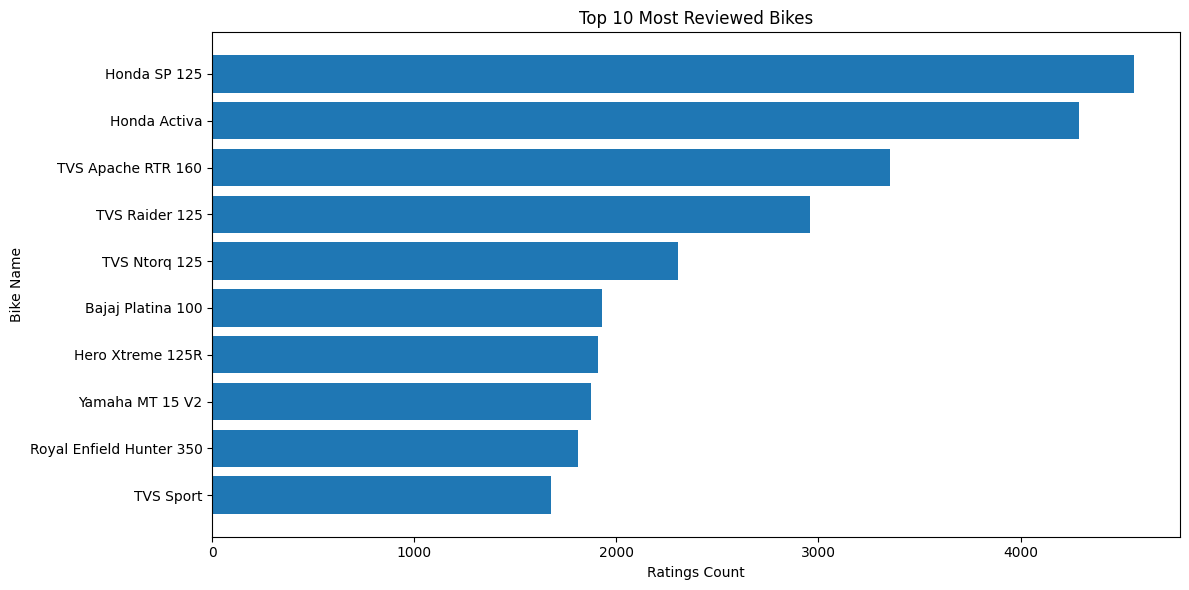

In [39]:
plt.figure(figsize=(12,6))

plt.barh(
    top_reviewed["Bike Name"],
    top_reviewed["Ratings Count"]
)

plt.title("Top 10 Most Reviewed Bikes")
plt.xlabel("Ratings Count")
plt.ylabel("Bike Name")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

11. Top 10 Rated Bikes

In [40]:
top_rated = (
    df[["Bike Name", "Rating"]]
    .sort_values("Rating", ascending=False)
    .head(10)
)

top_rated

,Bike Name,Rating
13,Royal Enfield Continental GT 650,4.8
18,Ather Konarc,4.8
49,Yamaha R15 V4,4.8
5,Royal Enfield Classic 350,4.7
4,Royal Enfield Hunter 350,4.7
12,Yamaha MT 15 V2,4.7
3,Bajaj Pulsar N160 2V,4.6
43,Hero Splendor Plus Xtec,4.6
16,Royal Enfield Meteor 350,4.6
44,Hero Passion Plus,4.6


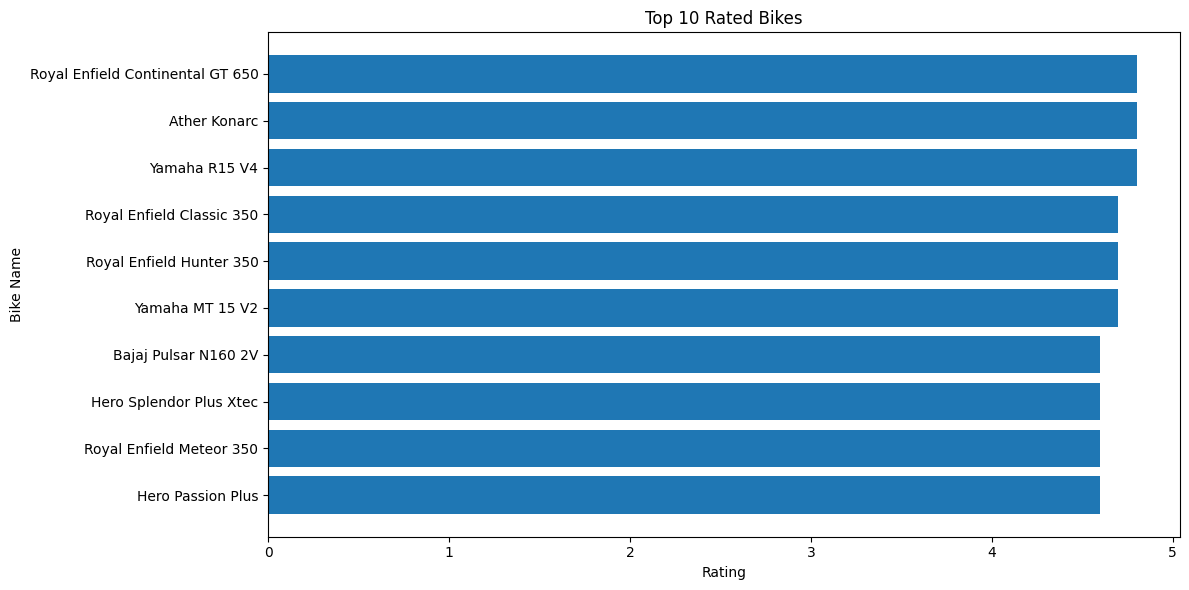

In [41]:
plt.figure(figsize=(12,6))

plt.barh(
    top_rated["Bike Name"],
    top_rated["Rating"]
)

plt.title("Top 10 Rated Bikes")
plt.xlabel("Rating")
plt.ylabel("Bike Name")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [42]:
correlation_columns = [
    "Price",
    "Rating",
    "Ratings Count",
    "Engine CC",
    "Mileage",
    "Power BHP",
    "Torque Nm",
    "Weight KG"
]

correlation = df[correlation_columns].corr()

correlation

,Price,Rating,Ratings Count,Engine CC,Mileage,Power BHP,Torque Nm,Weight KG
Price,1.000000,-0.503744,-0.315666,0.923426,-0.597327,0.961251,0.959269,0.595892
Rating,-0.503744,1.000000,0.106386,-0.533650,0.364097,-0.521647,-0.575971,-0.268940
Ratings Count,-0.315666,0.106386,1.000000,-0.354852,0.194218,-0.298191,-0.437919,-0.209882
Engine CC,0.923426,-0.533650,-0.354852,1.000000,-0.782567,0.916842,0.981861,0.847616
Mileage,-0.597327,0.364097,0.194218,-0.782567,1.000000,-0.636445,-0.815763,-0.702083
Power BHP,0.961251,-0.521647,-0.298191,0.916842,-0.636445,1.000000,0.941748,0.710807
Torque Nm,0.959269,-0.575971,-0.437919,0.981861,-0.815763,0.941748,1.000000,0.719392
Weight KG,0.595892,-0.268940,-0.209882,0.847616,-0.702083,0.710807,0.719392,1.000000


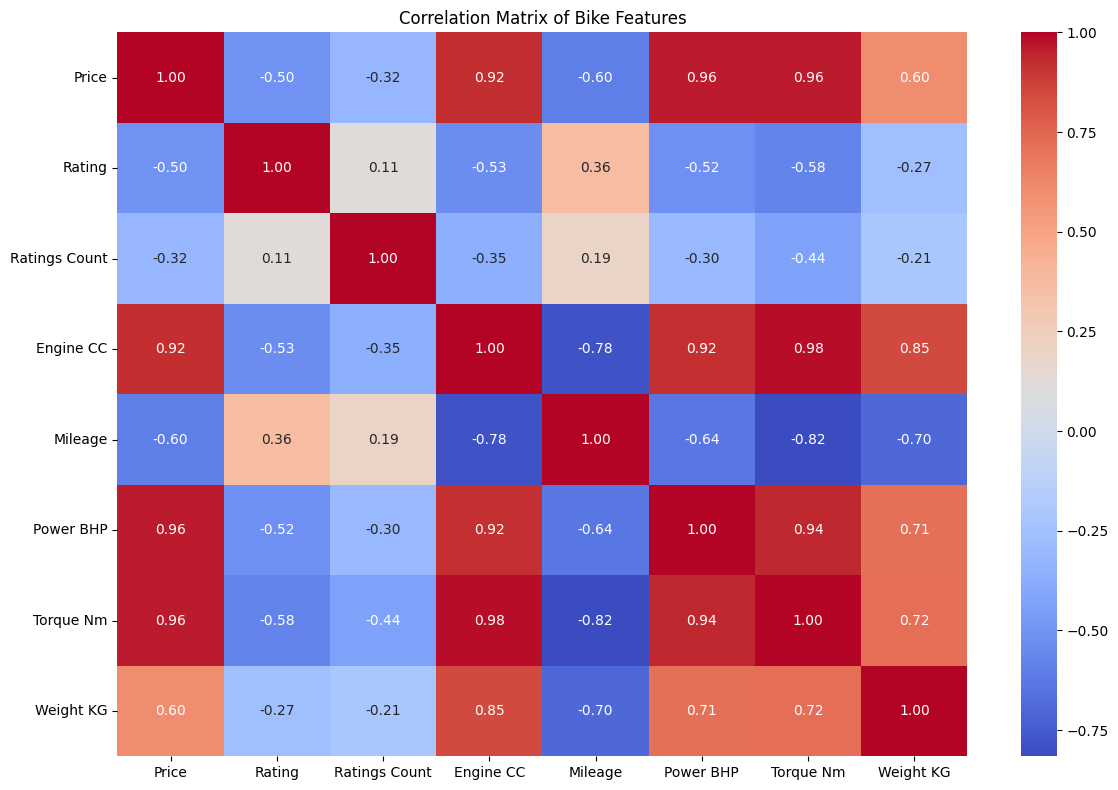

In [43]:
plt.figure(figsize=(12,8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Bike Features")
plt.tight_layout()
plt.show()

# BEST BIKE ANALYSIS

In [44]:
df["Rating Score"] = (
    df["Rating"] / df["Rating"].max()
)

df["Mileage Score"] = (
    df["Mileage"] / df["Mileage"].max()
)

df["Power Score"] = (
    df["Power BHP"] / df["Power BHP"].max()
)

df["Price Score"] = (
    1 - (df["Price"] - df["Price"].min()) /
    (df["Price"].max() - df["Price"].min())
)

print("Individual scores created successfully.")

Individual scores created successfully.


In [45]:
df["Best Bike Score"] = (
    df["Rating Score"] * 0.30 +
    df["Mileage Score"] * 0.25 +
    df["Power Score"] * 0.20 +
    df["Price Score"] * 0.25
)

print("Best Bike Score calculated successfully.")

Best Bike Score calculated successfully.


In [46]:
best_bikes = (
    df[
        [
            "Bike Name",
            "Brand",
            "Price",
            "Rating",
            "Mileage",
            "Power BHP",
            "Best Bike Score"
        ]
    ]
    .sort_values("Best Bike Score", ascending=False)
    .head(10)
)

best_bikes

,Bike Name,Brand,Price,Rating,Mileage,Power BHP,Best Bike Score
40,TVS Sport,Tvs,66200.0,4.4,80.0,8.08,0.782845
42,Bajaj Platina 100,Bajaj,71038.0,4.5,75.0,7.79,0.772563
43,Hero Splendor Plus Xtec,Hero,81361.0,4.6,73.0,7.90,0.771335
44,Hero Passion Plus,Hero,79535.0,4.6,71.0,7.91,0.765331
48,Hero Super Splendor Xtec,Hero,83928.0,4.5,69.0,10.72,0.754991
11,Hero Xtreme 125R,Hero,91000.0,4.6,66.0,11.40,0.751612
45,Bajaj CT 110,Bajaj,74847.0,4.4,70.0,8.48,0.750865
46,TVS Star City Plus,Tvs,72026.0,4.4,70.0,8.08,0.750841
47,Bajaj Platina 110,Bajaj,75798.0,4.4,70.0,8.48,0.750742
2,TVS Apache RTR 160,Tvs,110781.0,4.5,61.0,15.82,0.731471


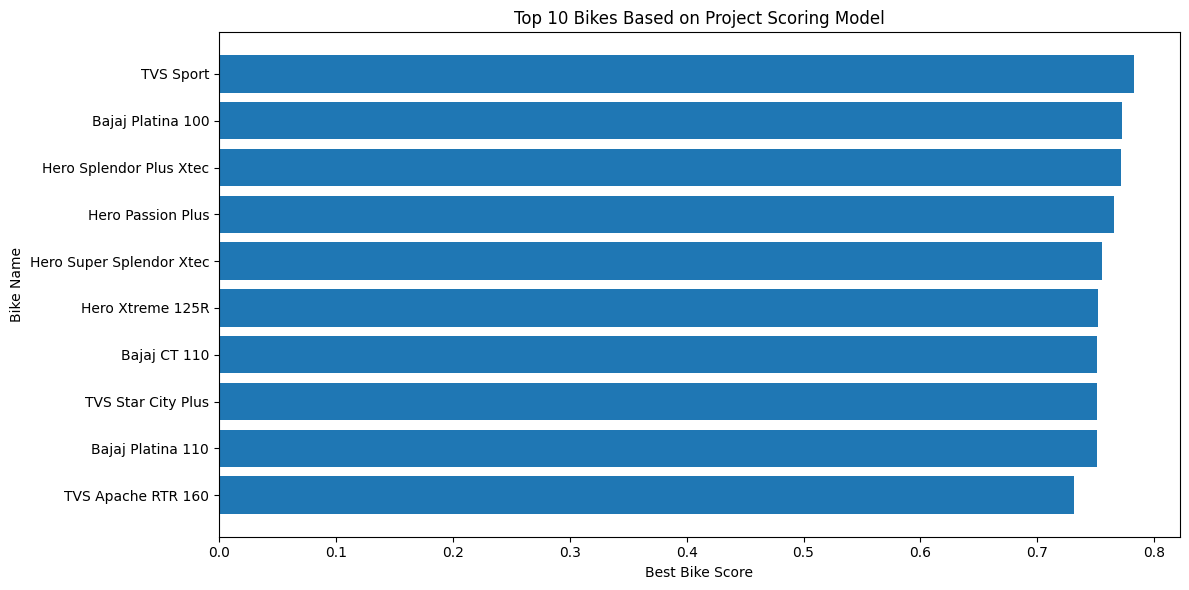

In [47]:
plt.figure(figsize=(12,6))

plt.barh(
    best_bikes["Bike Name"],
    best_bikes["Best Bike Score"]
)

plt.title("Top 10 Bikes Based on Project Scoring Model")
plt.xlabel("Best Bike Score")
plt.ylabel("Bike Name")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

# BUSINESS INSIGHTS

In [48]:
print("BUSINESS INSIGHTS")
print("=" * 60)

print("\n1. Brand Distribution")
print(df["Brand"].value_counts().head())

print("\n2. Average Price")
print(f"₹{df['Price'].mean():,.2f}")

print("\n3. Average Rating")
print(round(df["Rating"].mean(), 2))

print("\n4. Average Mileage")
print(round(df["Mileage"].mean(), 2))

print("\n5. Average Engine CC")
print(round(df["Engine CC"].mean(), 2))

print("\n6. Highest Powered Bike")
highest_power = df.loc[df["Power BHP"].idxmax(), "Bike Name"]
print(highest_power)

print("\n7. Highest Rated Bike")
highest_rated = df.loc[df["Rating"].idxmax(), "Bike Name"]
print(highest_rated)

print("\n8. Most Reviewed Bike")
most_reviewed = df.loc[df["Ratings Count"].idxmax(), "Bike Name"]
print(most_reviewed)

BUSINESS INSIGHTS

1. Brand Distribution
Brand
Tvs             9
Royalenfield    7
Honda           6
Hero            6
Bajaj           5
Name: count, dtype: int64

2. Average Price
₹239,412.56

3. Average Rating
3.55

4. Average Mileage
51.14

5. Average Engine CC
278.97

6. Highest Powered Bike
Norton Manx

7. Highest Rated Bike
Royal Enfield Continental GT 650

8. Most Reviewed Bike
Honda SP 125


# FINAL PROJECT SUMMARY

In [49]:
print("""
BIKEWALE BIKE ANALYTICS PROJECT
================================

Objective:
Analyze bikes in India based on price, mileage,
performance, engine capacity and user ratings.

Analysis Completed:
✓ Data Understanding
✓ Data Cleaning
✓ Brand Analysis
✓ Price Analysis
✓ Mileage Analysis
✓ Engine CC Analysis
✓ Power Analysis
✓ Rating Analysis
✓ Ratings Count Analysis
✓ Correlation Analysis
✓ Top 10 Bike Analysis
✓ Best Bike Scoring Model
✓ Business Insights
""")


BIKEWALE BIKE ANALYTICS PROJECT

Objective:
Analyze bikes in India based on price, mileage,
performance, engine capacity and user ratings.

Analysis Completed:
✓ Data Understanding
✓ Data Cleaning
✓ Brand Analysis
✓ Price Analysis
✓ Mileage Analysis
✓ Engine CC Analysis
✓ Power Analysis
✓ Rating Analysis
✓ Ratings Count Analysis
✓ Correlation Analysis
✓ Top 10 Bike Analysis
✓ Best Bike Scoring Model
✓ Business Insights



# FINAL CLEAN DATASET

In [50]:
final_columns = [
    "Bike Name",
    "Brand",
    "Price",
    "Rating",
    "Ratings Count",
    "Mileage",
    "Engine CC",
    "Power BHP",
    "Torque Nm",
    "Weight KG",
    "Price Category",
    "Engine CC Category",
    "URL"
]

final_df = df[final_columns]

final_df.head()

,Bike Name,Brand,Price,Rating,Ratings Count,Mileage,Engine CC,Power BHP,Torque Nm,Weight KG,Price Category,Engine CC Category,URL
0,Yezdi Roadster,Yezdi,201940.0,1.0,217.0,30.0,334.00,28.70,30.00,184.0,Premium,300-499 CC,https://www.bikewale.com/yezdi-bikes/roadster/
1,TVS Raider 125,Tvs,86397.0,4.4,2959.0,56.7,125.00,11.20,11.20,123.0,Budget,Below 125 CC,https://www.bikewale.com/tvs-bikes/raider-125/
2,TVS Apache RTR 160,Tvs,110781.0,4.5,3352.0,61.0,159.70,15.82,13.85,137.0,Mid-Range,125-199 CC,https://www.bikewale.com/tvs-bikes/apache-160/
3,Bajaj Pulsar N160 2V,Bajaj,122990.0,4.6,1282.0,51.6,164.82,15.68,14.65,148.0,Mid-Range,125-199 CC,https://www.bikewale.com/bajaj-bikes/pulsar-n160/
4,Royal Enfield Hunter 350,Royalenfield,137640.0,4.7,1811.0,36.2,349.00,20.20,27.00,181.0,Mid-Range,300-499 CC,https://www.bikewale.com/royalenfield-bikes/hu...


In [51]:
final_df.to_csv(
    "BikeWale_Final_Analysis_Dataset.csv",
    index=False
)

print("Final dataset saved successfully!")

Final dataset saved successfully!


In [52]:
files.download("BikeWale_Final_Analysis_Dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>